# Project 2 — Q5: classical cell matching and segmentation

**NYU Tandon · CS-GY 6643 · Fall 2026**  
**Team member(s) / NetID(s):** To be added

Traditional computer vision only. The refinement adds median denoising, optional multiscale blob detection, connected-mask cleanup, cell-triangle registration, guarded ICP and an optional area cost for assignment. All choices are shared across regions. No manual predictions, neural models, external data or test labels enter this pipeline.

**Target: 0.70 combined competition score.** Report the measured local scores below; this is not pixel accuracy or a verified Kaggle score. Earlier candidate CSVs and the separate U-Net experiment remain preserved.

## Data, sources and evaluation

Load native 16-bit TIFFs from project-relative `Data/`. There are 47 training regions from three mice and 29 hidden-test regions. Normalize derived processing arrays; source TIFFs are unchanged. RLE uses zero-based, row-major `start length` pairs, following L5 codelab cell 18.

**Sources:** L3 pp. 27–52 and codelab cells 6/8/21 (robust geometric fitting), L4 pp. 42–104 (filtering, segmentation and warping), L5 p. 111 and L6 p. 70 (cell segmentation/registration guidance). The triangle descriptors, preprocessing comparison and full automatic pipeline are project adaptations; known training pairs never initialize test predictions.

The reconstructed handout metric is `0.25 PQ_invivo + 0.25 PQ_exvivo + 0.50 F1_match`, with strict **IoU > 0.75**. Average PQ over regions and pool matching counts. Both masks must pass IoU for a verified correspondence to count. Unverified correspondences are not confirmed biological negatives, although they receive no matching credit. Official scorer/settings remain unverified; empty/empty PQ and all-empty F1 are locally defined as 1.

**Validation scope:** all three mice were previously inspected. Compare three retained preprocessing configurations and matching options by selecting on two mice and scoring the third. This is retrospective grouped development validation, not a fresh independent test. Earlier pilot/design decisions still reflect these data. Final inference parameters are selected on all released training regions after grouped evaluation.

Detailed trial counts and rejected preprocessing/registration comparisons are saved under `outputs/q5/refinement/`. The fold-selection cell reads these measured experiment tables; inference and the standalone CSV generator require only `Data/` and `cell_matching.py`.

In [1]:
from pathlib import Path
import json
import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
import tifffile
from scipy import ndimage as ndi
from skimage.segmentation import mark_boundaries
from matplotlib.patches import ConnectionPatch
from cell_matching import (REFINED_PARAMETERS as PARAMETERS, read_pair, normalize, predict_pair,
                           decode_rle, centers, evaluate, summarize, write_submission)

root, out = Path("Data"), Path("outputs/q5/refinement")
out.mkdir(parents=True, exist_ok=True)
train = pd.read_csv(root / "training/train_ground_truth.csv", dtype=str)
sample = pd.read_csv(root / "sample_submission.csv", dtype=str)
assert list(train.columns) == list(sample.columns)
assert train.sample_id.is_unique and sample.sample_id.is_unique
print(f"{len(train)} training regions, 3 mice; {len(sample)} hidden-test regions")
PARAMETERS

Matplotlib is building the font cache; this may take a moment.


47 training regions, 3 mice; 29 hidden-test regions


{'invivo': {'sigma': 2.5,
  'threshold': 0.025,
  'fraction': 0.2,
  'dilation': 1,
  'max_elongation': 3,
  'denoise': True,
  'multiscale': True,
  'clean': True},
 'exvivo': {'sigma': 3,
  'threshold': 0.12,
  'fraction': 0.2,
  'blobness': 0.6,
  'max_elongation': 3,
  'denoise': True,
  'clean': True},
 'matching': {'method': 'triangles',
  'gate': 8,
  'cutoff': 0.16,
  'guard': True,
  'shape_weight': 2}}

## 1. Preprocessing and instance masks

Percentile normalization preserves the source bit depth. A 3×3 median filter reduces isolated noise, followed by broad Gaussian background subtraction. Detect DoG peaks at the selected scale(s); ex-vivo Hessian filtering suppresses elongated bright processes. Marker-controlled watershed produces instances, trimmed relative to each basin's peak and checked for area/elongation. Keep each mask's largest connected component and fill holes while preserving neighboring labels. In-vivo masks retain the previous one-pixel expansion.

Pilot results rejected CLAHE and white top-hat preprocessing. Across all training regions, median filtering helped both modalities; multiple scales helped in vivo but hurt ex vivo. Closing and convex hulls were weaker than connected-component/hole cleanup. Compare the retained choices by mouse below. The automatically annotation-centered crop is for display only.

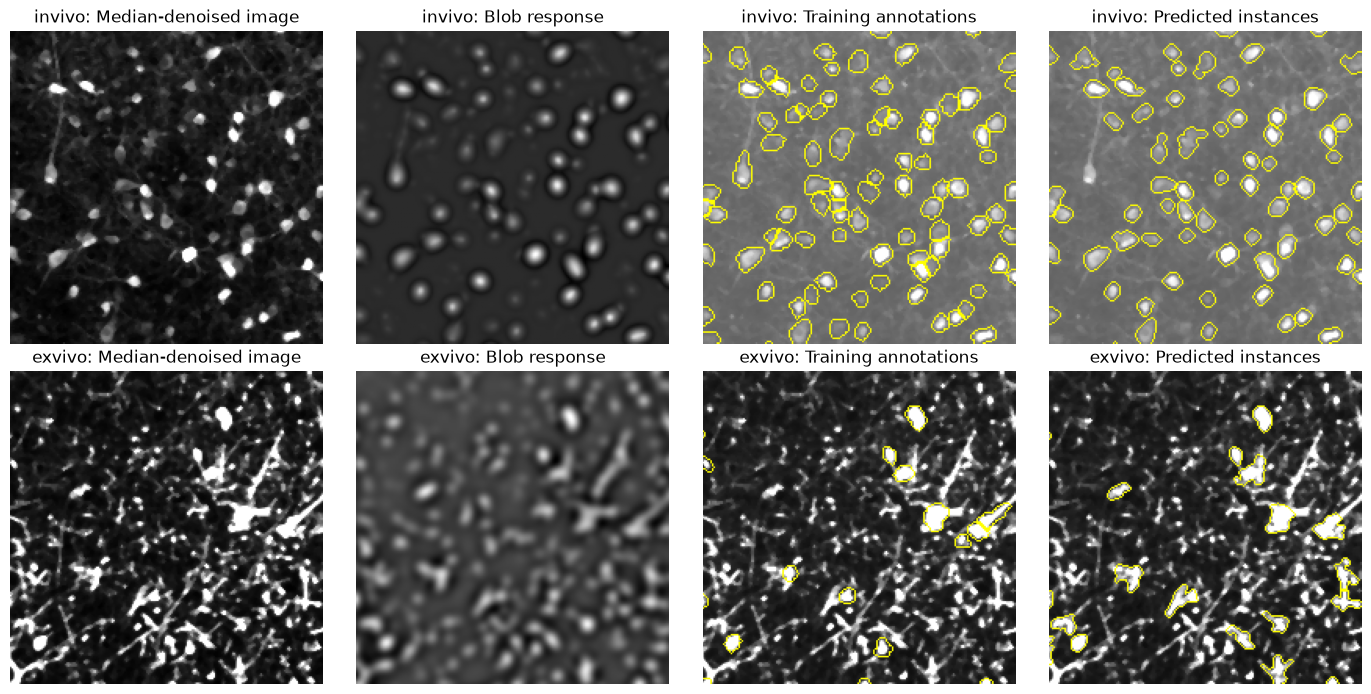

In [2]:
example = train.iloc[0]
images = read_pair(root / "training", example.sample_id)
labels, pairs, matrix, correlation = predict_pair(images, PARAMETERS)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for row, (image, prediction, modality) in enumerate(zip(images, labels, ["invivo", "exvivo"])):
    truth = np.zeros(image.shape, np.int32)
    for i, rle in enumerate(json.loads(example[modality + "_instances"]).values(), 1):
        truth[decode_rle(rle, image.shape)] = i
    y, x = np.median(np.argwhere(truth > 0), axis=0).astype(int)
    crop = np.s_[max(0, y-100):y+100, max(0, x-100):x+100]
    image_float = ndi.median_filter(normalize(image), size=3)
    signal = np.maximum(ndi.gaussian_filter(image_float, 1) - ndi.gaussian_filter(image_float, 10), 0)
    sigma = PARAMETERS[modality]["sigma"]
    scales = [sigma*.7, sigma, sigma*1.3] if PARAMETERS[modality].get("multiscale") else [sigma]
    response = np.maximum.reduce([ndi.gaussian_filter(signal, s) - ndi.gaussian_filter(signal, 1.6*s) for s in scales])
    pictures = [image_float[crop], response[crop], mark_boundaries(image_float[crop], truth[crop]),
                mark_boundaries(image_float[crop], prediction[crop])]
    for ax, picture, title in zip(axes[row], pictures, ["Median-denoised image", "Blob response", "Training annotations", "Predicted instances"]):
        ax.imshow(picture, cmap="gray")
        ax.set_title(f"{modality}: {title}")
        ax.axis("off")
    tifffile.imwrite(out / f"example_{modality}_labels.tif", prediction.astype(np.uint16))
plt.tight_layout()
plt.savefig(out / "segmentation_diagnostics.png", dpi=150)
plt.show()

## 2. Automatic registration and matching

Intensity correlation can confuse fibers and select a wrong tissue location. The alternative uses predicted cell centroids: describe local triangles by ordered side-length ratios and size, match descriptors, solve affine hypotheses, reject degenerate/reflected/extreme transforms, and rank/refine promising hypotheses using close mutual neighbors. Only predicted masks enter this calculation.

Compare this method with the existing correlation search. ICP can reject updates that decrease mutual-neighbor support. Hungarian assignment includes explicit unmatched options and optionally penalizes scale-adjusted area differences. Select method, distance gate, confidence cutoff and refinement/area options using development mice. Correlation and triangle-support scores have different meanings; neither is a probability.

Shared triangle constraints bound the search (singular values 0.8–1.2, rotation ±25°); a small/missing/ambiguous cell constellation can fail. Affine geometry cannot represent arbitrary tissue deformation.

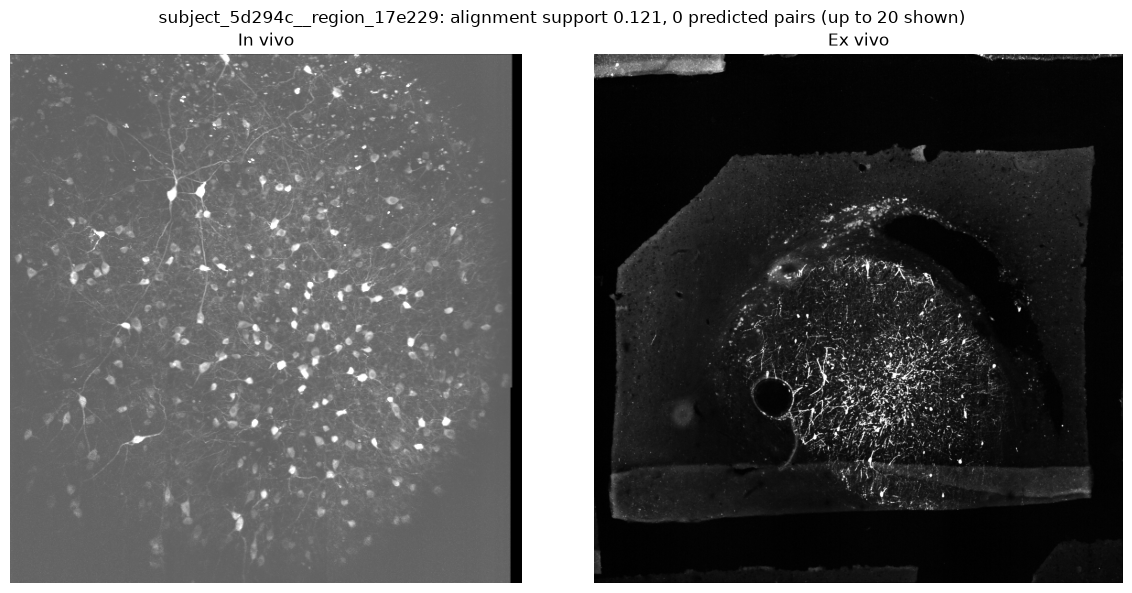

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, image, title in zip(axes, images, ["In vivo", "Ex vivo"]):
    ax.imshow(normalize(image), cmap="gray")
    ax.set_title(title)
    ax.axis("off")
a, b = [centers(mask) for mask in labels]
for i, j in pairs[:20]:
    fig.add_artist(ConnectionPatch(a[i-1], b[j-1], "data", "data", axesA=axes[0], axesB=axes[1],
                                  color="lime", linewidth=.7, alpha=.7))
fig.suptitle(f"{example.sample_id}: alignment support {correlation:.3f}, {len(pairs)} predicted pairs (up to 20 shown)")
plt.tight_layout()
plt.savefig(out / "matching_diagnostics.png", dpi=150)
plt.show()

## 3. Retrospective mouse-grouped selection

The measured candidate tables contain native-image evaluations for each retained preprocessing configuration, registration method, ICP guard, area cost and gate. For each fold, choose the complete candidate on the other two mice, then report the scored mouse. Pool out-of-fold pair counts; do not average regional F1s.

`B`: denoised multiscale in-vivo masks with fraction 0.20; denoised ex-vivo masks with Hessian cutoff 0.45 and fraction 0.15. `C`: B with ex-vivo fraction 0.20 and its original Hessian cutoff 0.60. `D`: C with single-scale in-vivo detection. All include connected-component/hole cleanup. These are shared candidate parameters, not sample-specific branches.

In [4]:
variants = {
    "B": ("matching_candidates.csv", dict(multiscale=True), dict(blobness=.45, fraction=.15)),
    "C": ("matching_candidates_C.csv", dict(multiscale=True), dict(blobness=.6, fraction=.2)),
    "D": ("matching_candidates_D.csv", dict(multiscale=False), dict(blobness=.6, fraction=.2)),
}
raw = pd.concat([pd.read_csv(out / path).assign(variant=name)
                 for name, (path, _, _) in variants.items()], ignore_index=True)
assert all(set(g.sample_id) == set(train.sample_id) for _, g in raw.groupby("variant"))
keys = ["variant", "method", "guard", "shape_weight", "gate", "cutoff"]
options = []
for method, group in raw.groupby("method"):
    for cutoff in ([0, .10, .12, .14, .16, .18] if method == "correlation" else [0, .08, .12, .16, .20, .24]):
        frame = group.assign(cutoff=cutoff).copy()
        frame.loc[frame.confidence < cutoff, ["correct_pairs", "predicted_pairs"]] = 0
        options.append(frame)
candidates = pd.concat(options, ignore_index=True)

def choose(frame):
    choices = [dict(zip(keys, values), **summarize(group)) for values, group in frame.groupby(keys)]
    return max(choices, key=lambda choice: choice["score"])

folds, selections = [], []
for subject in sorted(candidates.subject.unique()):
    best = choose(candidates[candidates.subject != subject])
    keep = candidates.subject.eq(subject)
    for key in keys:
        keep &= candidates[key].eq(best[key])
    fold = candidates[keep]
    folds.append(fold)
    selections.append(dict(subject=subject, **{k: best[k] for k in keys}, **summarize(fold)))
metrics = pd.concat(folds)
summary, final_choice = summarize(metrics), choose(candidates)
metrics.to_csv(out / "grouped_metrics.csv", index=False)
(out / "grouped_summary.json").write_text(json.dumps(dict(**summary, folds=selections, final_choice=final_choice), indent=2))
display(pd.DataFrame(selections).set_index("subject").round(4))
previous = pd.read_csv("outputs/q5/lecture6_cv_metrics.csv")
display(pd.DataFrame([summarize(previous), summary], index=["Previous grouped development", "Refined grouped development"]).round(4))
_, iv, ex = variants[final_choice["variant"]]
assert all(PARAMETERS["invivo"][k] == v for k, v in iv.items())
assert all(PARAMETERS["exvivo"][k] == v for k, v in ex.items())
assert all(PARAMETERS["matching"][k] == final_choice[k] for k in ["method", "guard", "shape_weight", "gate", "cutoff"])
print(f"Grouped score: {summary['score']:.4f}; target 0.7000 {'reached' if summary['score'] >= .7 else 'NOT reached'}")
print("Deployment choice (fitted on all training data):", final_choice)

,variant,method,guard,shape_weight,gate,cutoff,pq_invivo,pq_exvivo,f1_match,score
subject,,,,,,,,,,
subject_5d294c,C,triangles,True,2,8,0.16,0.4712,0.2362,0.1232,0.2384
subject_b2ba5e,C,triangles,True,2,8,0.16,0.4046,0.1434,0.0690,0.1715
subject_db6b8b,C,correlation,True,0,8,0.12,0.4731,0.3219,0.0870,0.2422


,pq_invivo,pq_exvivo,f1_match,score
Previous grouped development,0.3746,0.2005,0.0447,0.1661
Refined grouped development,0.4535,0.2434,0.0957,0.2221


Grouped score: 0.2221; target 0.7000 NOT reached
Deployment choice (fitted on all training data): {'variant': 'C', 'method': 'triangles', 'guard': True, 'shape_weight': 2, 'gate': 8, 'cutoff': 0.16, 'pq_invivo': 0.4534815161111121, 'pq_exvivo': 0.2433787669491611, 'f1_match': 0.15978552278820377, 'score': 0.2541078321591702}


In [5]:
# Independently rerun the final deployment pipeline on all released training regions.
records = []
for row in train.itertuples(index=False):
    prediction, matched, _, support = predict_pair(read_pair(root / "training", row.sample_id), PARAMETERS)
    records.append(dict(sample_id=row.sample_id, confidence=support, **evaluate(prediction, matched, row)))
final_metrics = pd.DataFrame(records)
final_metrics.to_csv(out / "final_training_metrics.csv", index=False)
fitted = summarize(final_metrics)
for key, value in fitted.items():
    np.testing.assert_allclose(value, final_choice[key], rtol=0, atol=1e-12)
display(pd.DataFrame([fitted], index=["Fitted deployment; not held-out"]).round(4))
r, v = final_metrics.recoverable_pairs.sum(), final_metrics.verified_pairs.sum()
ceiling = .25*(fitted["pq_invivo"]+fitted["pq_exvivo"]) + r/(r+v)
print(f"Fixed-mask ideal-matching upper bound: {ceiling:.4f}; recoverable pairs {r}/{v}")

,pq_invivo,pq_exvivo,f1_match,score
Fitted deployment; not held-out,0.4535,0.2434,0.1598,0.2541


Fixed-mask ideal-matching upper bound: 0.3693; recoverable pairs 276/1139


### Inspect strong and weak alignment-support hypotheses

Choose the highest- and lowest-support training regions automatically under the final deployment method. Red is warped in-vivo intensity; green is ex-vivo intensity. Yellow indicates coincident brightness, not proven correspondence. Crops come from the computed source footprint.

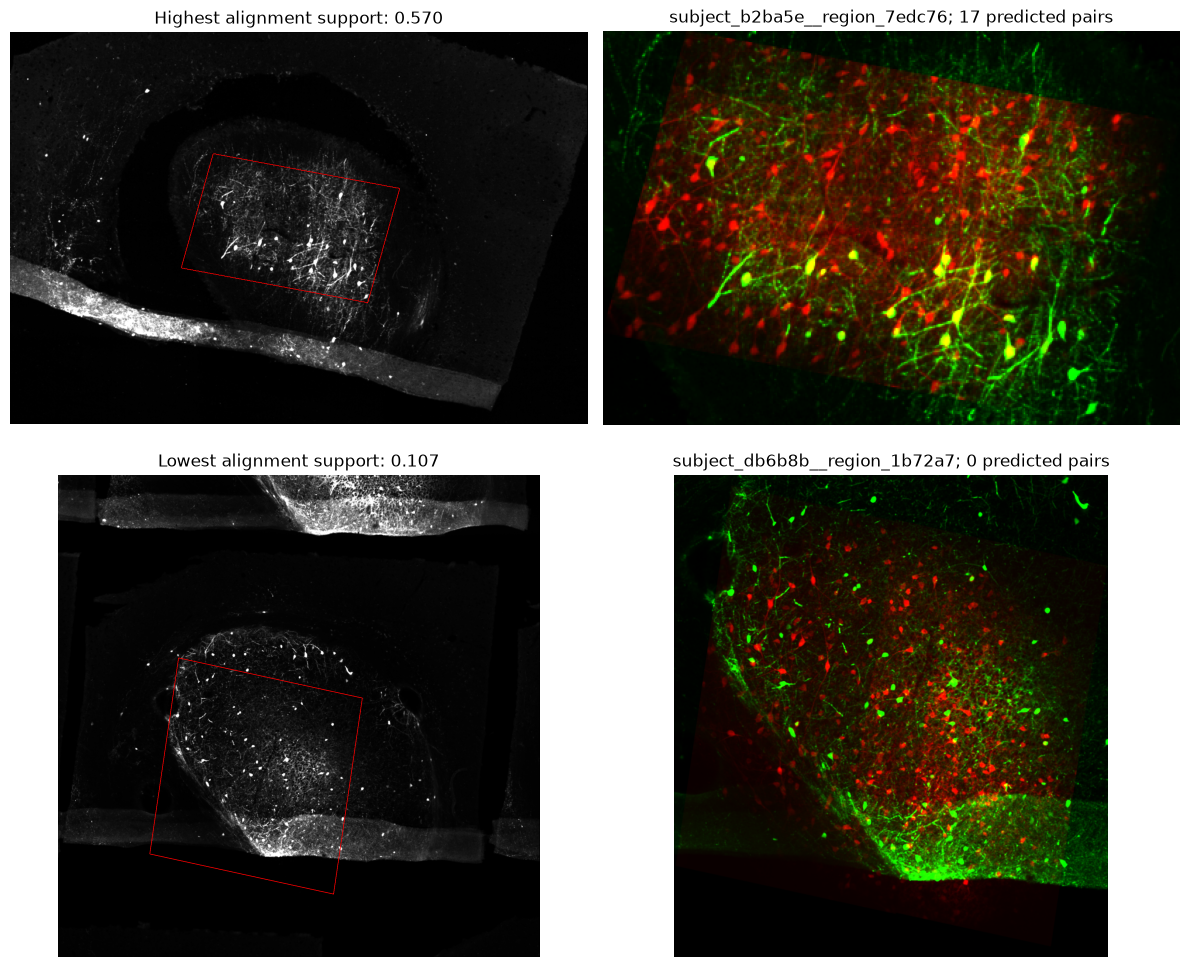

In [6]:
ranked = final_metrics.sort_values("confidence")
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for row_index, position in enumerate([-1, 0]):
    sample_id = ranked.iloc[position].sample_id
    image_pair = read_pair(root / "training", sample_id)
    _, matched, transform, confidence = predict_pair(image_pair, PARAMETERS)
    if transform is None:
        continue
    source, target = [normalize(im) for im in image_pair]
    h, w = target.shape
    warped = cv2.warpAffine(source, transform, (w, h))
    support = cv2.warpAffine(np.ones(source.shape, np.uint8), transform, (w, h)) > 0
    y, x = np.where(support)
    if not len(x):
        continue
    crop = np.s_[y.min():y.max()+1, x.min():x.max()+1]
    overlay = np.dstack([warped, target, np.zeros_like(target)])
    axes[row_index, 0].imshow(target, cmap="gray")
    axes[row_index, 0].contour(support, levels=[.5], colors="red", linewidths=.5)
    axes[row_index, 1].imshow(overlay[crop])
    axes[row_index, 0].set_title(f"{'Highest' if position == -1 else 'Lowest'} alignment support: {confidence:.3f}")
    axes[row_index, 1].set_title(f"{sample_id}; {len(matched)} predicted pairs")
    for ax in axes[row_index]:
        ax.axis("off")
plt.tight_layout()
plt.savefig(out / "alignment_overlays.png", dpi=150)
plt.show()

## 4. Generate and validate the new candidate CSV

Read the released sample IDs in original order, predict native-size masks and one-to-one matches, and encode JSON/RLE using proper CSV quoting. Validate all masks, identifiers, uniqueness and round trips. Keep both older candidates.

Independent reproduction:

```bash
.venv/bin/python cell_matching.py --data Data --output "Kaggle Submissions/classical_refined.csv"
.venv/bin/python -m unittest test_cell_matching.py
```

This writes a local candidate; no Kaggle upload or final selection is performed. No new dependencies are required. Legacy helper defaults remain preserved for the separate U-Net notebook.

In [7]:
submission = write_submission(root, "Kaggle Submissions/classical_refined.csv", PARAMETERS)
print(f"Validated {len(submission)} rows; saved classical_refined.csv")
display(submission[["sample_id"]].head())

subject_78b6a7__region_33daed: 340/112 cells, 0 pairs, correlation=0.101


subject_78b6a7__region_64dd4d: 243/63 cells, 17 pairs, correlation=0.175


subject_78b6a7__region_7754ed: 309/68 cells, 0 pairs, correlation=0.131


subject_78b6a7__region_798993: 352/79 cells, 0 pairs, correlation=0.143


subject_78b6a7__region_7c48e3: 324/91 cells, 0 pairs, correlation=0.113


...

subject_d7a97c__region_d472db: 341/107 cells, 0 pairs, correlation=0.111


subject_d7a97c__region_dd13e1: 321/39 cells, 11 pairs, correlation=0.174


subject_d7a97c__region_f24078: 341/143 cells, 0 pairs, correlation=0.080


Validated 29 rows; saved classical_refined.csv


,sample_id
0,subject_78b6a7__region_33daed
1,subject_78b6a7__region_64dd4d
2,subject_78b6a7__region_7754ed
3,subject_78b6a7__region_798993
4,subject_78b6a7__region_7c48e3


## Results and limitations

Use the grouped table above to assess this refinement; the all-training deployment score is fitted, and the ideal-matching bound is hypothetical. The 0.70 target is not an achieved score unless explicitly shown by measured evaluation. Strict mask IoU, missing dim ex-vivo cells, false fiber detections and ambiguous tissue locations remain bottlenecks.

The supplied data were already used in earlier method design. Even mouse-grouped selection here is retrospective development, not an untouched or official leaderboard test. No hidden labels, hand-edited predictions, per-test-ID rules, learned models or external data were used. The previous CSVs, Q1–Q4, U-Net experiment and frozen README are preserved.

## AI assistance and actual prompt record

OpenAI Codex assisted with the classical implementation, experiments and verification.

# AI Assistance Record — Project 2

## Tools and scope

During initial setup on 2026-10-06, OpenAI Codex assisted with reading the previous project's workflow and both Project 2 handouts, preparing project instructions, downloading official Q1–Q4 data, initializing the Python environment, and creating Markdown-only notebook scaffolds. No question was solved during setup. Later source review and Q1 implementation are recorded chronologically below.

Keep actual user prompts in chronological order. Add subsequent assistance here and include the required disclosure/prompt chain in final deliverables. Do not reconstruct unavailable prompts or include hidden model reasoning.

## Request 1 — 2026-10-06

The user referenced `../Project1/AGENTS.md` and attached a screenshot of the previous project's directory structure. The request text was:

> Go through the AGENTS.md file for the previous project of this course, we will be following similar workflow for this project as well. Understand the requirements for this project by going through the project material present in the two pdfs present in the project root. Create a AGENTS.md file similar to one uploaded from the previous project with emaphasis on simple and minila code, we will follow the similar project structure as the project 1. For this task create the directories and download the data for Q1-4 we will solve this in subsequent tasks and the solutions and concepts used in it will the foundation upon which will we solve the kaggle competition problem. Also initialize the virtual python environment and install the required libraries. Add basic README.md we wont update it  until after the project solution is finished and ready to submit. Just create the solution notebooks and just add Heading markdown cells with boilerplate information about what it contains don't add code yet. In next tasks I will provide the lecture slides and the codelab notbooks the concepts and code from will we will use to solve this assignment.

## Request 2 — 2026-10-06

> Commit and push the repository to [https://github.com/rohitfarfad/-CV-Cell-Matching-x-Segmentation.git](https://github.com/rohitfarfad/-CV-Cell-Matching-x-Segmentation.git)

Assistance: inspect the local and remote Git state, prepare the initial setup commit, and push it to the user-specified repository. Existing dataset, environment, and generated-output exclusions are retained.

## Request 3 — 2026-10-08

The user supplied Lecture 3, 4, 5, and 6 PDFs; their exact paths are recorded in `AGENTS.md` §6.

> Go through this slides and understand the concepts covered  in the lectures. Update the AGENTS.md briefly to use these concepts in the solutions

Assistance: review the four slide decks, map their concepts to Q1–Q5, and record the later deadline extension and Q5-specific guidance. No solution code or notebook changes.

## Request 4 — 2026-10-08

The message listed the four lecture PDFs; the corresponding local code notebooks were found in `../Lectures/CodeLabs/` and are identified in `AGENTS.md` §6.1.

> Go through these codelabs and understand the code and concepts discussed. We will use this code to solve the porblems.

Assistance: review four relevant local codelabs, record reusable snippets and adaptation issues, and check the supplied RLE functions on five synthetic masks. The solution notebooks and README were not changed; no models were downloaded or trained.

## Request 5 — 2026-10-08

> Using the concepts covered in the class, how do you solve the Question 1, give the overview of the approach before we code it

Assistance: explain a classical approach combining edge detection, pavement–grass color evidence, RANSAC line fitting, and pair geometry checks. No code was added in that turn.

## Request 6 — 2026-10-08

> great, let's code it in the notebook

Assistance: implement Q1 in `Q1to4Solution.ipynb`, adapting class RANSAC/SVD, Canny, thresholding and color-feature concepts; inspect the programmatically annotated result and retain diagnostics and explanations. Q2–Q5 and README remain unchanged. No hidden ground truth, manual coordinates, or learned models are used.

Validation: the notebook executed in a fresh kernel without cell errors, saved the annotated image and visible figures, and passed original-input hash and unchanged-placeholder checks. Residuals describe the fitted edge consensus, not hidden-ground-truth accuracy.

## Request 7 — 2026-10-08

> Use minimum code

## Request 8 — 2026-10-08

> Continue, use minimal tokens

Assistance: reduced Q1 from 133 to 67 nonblank code lines, removed redundant plots/table dependencies, and reran the notebook. The generated boundary image is byte-identical to the previous result.

## Request 9 — 2026-10-08

> For question1, add the final solution images in origianl image resolution and after that give the overview of the solution for question 2 using concepts covered in the class

Assistance: embed the original and annotated Q1 images at native 1280 × 850 resolution; outline SIFT matching, RANSAC homography estimation, perspective warping and mask-based compositing for Q2. No Q2 solution code added.

## Request 10 — 2026-10-08

> Great, add the solution for question 2 in the notebook with minimum code and optimizing the token usage

Assistance: implement a concise SIFT/ratio-test/RANSAC homography solution, warp and composite the replacement at original scene resolution, inspect the result, and document the small boundary mismatch caused by the curved cover. No manual coordinates or learned methods; README and Q3–Q5 remain unchanged.

## Request 11 — 2026-10-08

> You can add the code for question 2 to show important intermediate steps of the solution

Assistance: add concise visualizations of ratio-test matches, RANSAC inliers, the projected cover boundary, compositing mask and warped artwork. Display subsets/crops are labeled and computed automatically; fitting and final compositing remain unchanged.

## Request 12 — 2026-10-08

> Great, similary give the overview of solution for question 3 before coding

Assistance: inspect all six inputs and outline feature-based distortion correction, overlap inference, transform composition, canvas calculation and blending. No solution code added in that turn.

## Request 13 — 2026-10-08

> Great, let's add the solution to the notebook, keep the code minimum but include the important intermediate steps to the final solution, add final solution image in original dimentions

Assistance: implement Q3 with automatic padding-based distortion identification, SIFT/RANSAC overlap estimation, transform composition, image-derived cylindrical projection and feather blending. The cylinder addresses an observed projective-horizon failure in a flat-canvas trial. Include intermediate figures and the full-resolution panorama; document calibration assumptions and residual limitations. No hard-coded transforms/order, manual alignment, or high-level stitcher.

## Request 14 — 2026-10-08

> similarly give the overview of solution for question 4

Assistance: inspect the wildlife images and JSON clicks, and outline click-initialized GrabCut, conservative component cleanup, intermediate displays and original-resolution RGBA export.

## Request 15 — 2026-10-08

> Great let's code this into the notebook like previous questions

Assistance: implement classical click-guided GrabCut, compare initialization/spatial and edge-aware alternatives on the supplied images, and retain a common RGB-plus-spatial-cut baseline. Add diagnostic figures, original-resolution RGBA outputs, and explicit caveats about retained background and missing animal parts. No extra manual annotations or learned semantic models; image quality remains insufficient for a claim of complete animal isolation.

## Request 16 — Q4 refinement

> current solution is good but it's still very choppy and isn't very clode to the expected segments, in the first one the segment include large part of the tree along with the lizard, in second the large portion of the leopard's face is missing as well as the rear part and tail and part of rock and backgroud is also included, in third the the part of the tree is visible. Try to fix this, part of the problem it seems the subjects are clamoflaged well in the background. Try to resolve this issue without hardcoding the solutions. Try any other concepts of tricks from the lecture, use external knowledge if necessary. Course is derived from the Computer Vision: Algorithms and Applications textbook by Richard Szeliski. Check it for reference if anything from there might be usefule. Try to keep the code changes minimum and optimize the token usage.

## Request 17 — 2026-10-09

> Continue the work

Assistance: review Szeliski §§5.4–5.5 (February 2010 draft), compare classical texture/graph alternatives, and replace the Q4 color-cut intersection with shared Lab/Gabor superpixel geodesic segmentation and original-resolution GrabCut boundary refinement. No manual coordinates, mask corrections, learned models, new packages or per-image algorithm branches. Retain intermediate figures and explain both visual improvements and remaining bark/rock leakage and missing tail detail. README, Q1–Q3 implementation and Q5 remain unchanged.

## Request 18 — 2026-10-09

> Great now using these answers as foundation solve the kaggle competition with minimum code and optimize the token usage. Aim for 70 percent accuracy. Use only traditional Computer vision methods, stick to the competion description here is the link to competition [https://www.kaggle.com/competitions/testingpj-2](https://www.kaggle.com/competitions/testingpj-2)

Assistance: inspected Q5 handout and L5 RLE/registration examples; attempted official Kaggle access (data API HTTP 401), checked the empty Data folder and local Downloads archives, and requested the dataset path. Prepared the Q5 notebook's dataset/schema check, classical-only validation plan and codelab-derived RLE helpers. Real-image implementation, tuning, scoring and submission generation require the official dataset; no performance is claimed.

## Request 19 — 2026-10-09

> I have downloaded and copied the data in /Data directory

Assistance: verified the user-provided Q5 dataset and recorded 154 hashes; implemented a traditional blob/Hessian/watershed segmentation and correlation/RANSAC/Hungarian matching pipeline in `cell_matching.py`, with notebook diagnostics and a CSV generator. Compared segmentation and registration variants on development mice, selected shared modality parameters on 29 development regions, froze them before evaluating the remaining 18 regions, and retained all test IDs for submission generation. Six synthetic contract tests cover RLE, strict mask IoU, pair scoring, pooled F1, unmatched cells and image translation; these are not accuracy measurements. No learned models, test labels, manual corrections or per-test-ID tuning. The requested 0.70 score is a target, not an achieved or guaranteed result. Actual results are recorded in the notebook and `outputs/q5/validation_summary.csv`. No Kaggle upload performed.

## Request 20 — 2026-10-09

The user supplied the Lecture 6 “Tips and Tricks for Project 2” slide.

> try to improve the score, try the tips and tricks mentioned in lecture 6

## Request 21 — 2026-10-09

> continue the work, optimize the token usage

Assistance: apply the slide's traditional-method guidance: reject elongated masks, search affine initialization with unequal scales and shear, refine using close mutual predicted-centroid matches and full-affine RANSAC ICP, retain Hungarian one-to-one matching, and add warped-image overlays. Compare new shape/gating choices with leave-one-mouse-out selection. Since earlier development already inspected these mice, call the results retrospective grouped validation, not a new untouched test. Preserve the traditional-only restriction; do not use the slide's neural fine-tuning, Dice/focal-loss or pretrained-model suggestions. Actual scores and checks are recorded in the notebook and AGENTS.md.

## Request 22 — 2026-10-09

> this is no where close to required, Just as an experiment try small U-Net cnn model in separate notebook

Assistance: create `SmallUNetExperiment.ipynb` as an explicitly authorized neural experiment while preserving the classical solution. Install optional PyTorch, implement two small U-Nets from scratch for the modalities, train fixed-budget models on two mice using foreground/core supervision, augmented cell/background patches and BCE + Dice loss, and evaluate the excluded mouse with fixed postprocessing and unchanged classical registration/matching. Save checkpoints, metrics and figures separately. No pretrained weights, external data or Kaggle upload; the previously inspected evaluation mouse is not claimed as a fresh independent test. Actual scores are recorded in the notebook and experiment outputs.


## Request 23 — 2026-10-09

> Go through the Kaggle competitiono implementation and the work already done

Assistance: reviewed both Q5 notebooks, classical helper code, saved metrics and candidate CSVs; reran contract tests and submission validation; summarized local results, segmentation/matching bottlenecks and remaining deliverables. No prediction changes or uploads in that review.

## Request 24 — 2026-10-09

> What are the weaknesses in the current classical implementation, and what can be done to improve the performance

Assistance: inspected per-region and parameter-selection results; explained detection scale, mask-boundary, registration, ICP and assignment weaknesses. Consulted official scikit-image/OpenCV documentation and proposed classical preprocessing, segmentation and geometry improvements. No prediction changes in that review.

## Request 25 — 2026-10-09

> Ok let's try applying these fixes and aim to get 70 percent accuracy, also see if we can do some preprocessing on data to improve the results, try to keep code changes to minimum and optimize the token usage

Assistance: compared median/CLAHE/top-hat preprocessing, single/multiscale detection, boundary fractions and mask cleanup; tested intensity/cell-response registration, SIFT, multiple correlation hypotheses and local cell-triangle matching. Kept denoising, multiscale in-vivo detection, revised boundaries, component/hole cleanup, triangle registration, guarded ICP and an optional area assignment cost. Select complete retained candidates using two mice and score the third, then select deployment settings on all released training data. All data were previously inspected: this remains retrospective development validation. Keep the traditional-only pipeline, preserve the separate U-Net experiment and its legacy helper defaults, source inputs, Q1–Q4, earlier CSVs and README. Generate a new local candidate only; no Kaggle upload. Measured grouped score 0.2221 versus previous 0.1661; fitted deployment score 0.2541. The 0.70 target is not achieved. Reproduction checks are recorded in AGENTS.md after execution.
